# Breakfast Hour - Monday, Week 2
### Data Visualization Review (Matplotlib & Seaborn)
Author: Katie Sylvia, Loren Dunn, RS

Data set in the data folder as `auto_mpg_dataset.csv`. Dataset is of cars from the 1970s and 1980s.<br>
Data from: https://www.mldata.io/datasets-sort/regression/<br>

This data has <a href="https://archive.ics.uci.edu/ml/datasets/auto+mpg">academic origins.  (Carnegie Mellon StatLib Library.)</a> For today, we'll pretend we've been given this data by the product team.

In [197]:
# Import Libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [198]:
# Read in the data
df = pd.read_csv('./data/auto_mpg_dataset.csv')

In [245]:
# Check .info(). 
df.info()

# What do we get from this, and why does it matter?:

<class 'pandas.core.frame.DataFrame'>
Int64Index: 392 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cylinders     392 non-null    int64  
 1   displacement  392 non-null    float64
 2   horsepower    392 non-null    float64
 3   weight        392 non-null    float64
 4   acceleration  392 non-null    float64
 5   model_year    392 non-null    int64  
 6   mpg           392 non-null    float64
dtypes: float64(5), int64(2)
memory usage: 32.6 KB


In [200]:
# Display the first 5 rows
df.head(5)

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu,18.0
1,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320,15.0
2,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite,18.0
3,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst,16.0
4,8,302.0,140.0,3449.0,10.5,70,1,ford torino,17.0


## Data Cleaning

Before starting a project, do a quick audit of your data. This will help you set expectations and plan your time.

Is the data:
1. *There?*
2. Typo-free?
3. Reasonable?


#### 1. *There*, and in the correct format

In [202]:
# Check for null values
df.isnull().sum()

cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
mpg             0
dtype: int64

In [203]:
# Check the datatypes
df.dtypes

cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name         object
mpg             float64
dtype: object

In [205]:
# Check duplicates
df.duplicated(subset = ['car_name']) # pd Series of boolean values.

0      False
1      False
2      False
3      False
4      False
       ...  
393    False
394    False
395    False
396    False
397    False
Length: 398, dtype: bool

In [206]:
df[df.duplicated(subset = ['car_name', 'model_year'], keep = False)]

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
168,4,140.0,83.0,2639.0,17.0,75,1,ford pinto,23.0
174,6,171.0,97.0,2984.0,14.5,75,1,ford pinto,18.0
338,4,135.0,84.0,2490.0,15.7,81,1,plymouth reliant,27.2
342,4,135.0,84.0,2385.0,12.9,81,1,plymouth reliant,30.0


In [207]:
df.groupby(by = ['car_name', 'model_year']).count().sort_values(by = 'cylinders', ascending = False).head(3)

,,cylinders,displacement,horsepower,weight,acceleration,origin,mpg
car_name,model_year,,,,,,,
ford pinto,75,2,2,2,2,2,2,2
plymouth reliant,81,2,2,2,2,2,2,2
oldsmobile cutlass ciera (diesel),82,1,1,1,1,1,1,1


#### 2. Typo-free

In [208]:
# Check the make of the cars. Return unique values for the first word in the string.

print(sorted(list(df['car_name'].apply(lambda x:x.split()[0]).unique())))

['amc', 'audi', 'bmw', 'buick', 'cadillac', 'capri', 'chevroelt', 'chevrolet', 'chevy', 'chrysler', 'datsun', 'dodge', 'fiat', 'ford', 'hi', 'honda', 'maxda', 'mazda', 'mercedes', 'mercedes-benz', 'mercury', 'nissan', 'oldsmobile', 'opel', 'peugeot', 'plymouth', 'pontiac', 'renault', 'saab', 'subaru', 'toyota', 'toyouta', 'triumph', 'vokswagen', 'volkswagen', 'volvo', 'vw']


I asked ChatGPT to fix it. Do you notice any problems with the dictionary it wrote?

In [209]:
gpt_dict = {'chevroelt': 'chevrolet', 'hi': 'honda', 'maxda': 'mazda', 'toyouta': 'toyota', 'vokswagen': 'volkswagen'} 

# Missing vw, missing mercedes, HI is international harvester

In [211]:
df[df['car_name'].str.contains("hi")]

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
28,8,304.0,193.0,4732.0,18.5,70,1,hi 1200d,9.0
200,6,250.0,78.0,3574.0,21.0,76,1,ford granada ghia,18.0
251,8,302.0,139.0,3570.0,12.8,78,1,mercury monarch ghia,20.2


In [212]:
# Fix it
new_dict = {'chevroelt': 'chevrolet', 'hi': 'international_harvester', 
            'maxda': 'mazda', 'toyouta': 'toyota', 'vokswagen': 'volkswagen', 'vw': 'volkswagen',
            'mercedes': 'mercedes-benz', 'benz': ''}

In [213]:
# Mapping replacement text
df['car_name'] = df['car_name'].apply(lambda x:" ".join(new_dict.get(i, i) for i in x.split()))

In [247]:
# What does this tell us about our data?


#### 3. Reasonable

In [ ]:
# If we had time, we'd fill out the car facts table

| 1980s  🚗s      | reasonable values | notes/questions |
| ----------- | ----------- | ----------- |
| mpg      | ? - ?       |  Text        |
| horsepower   | ? - ?        |  Text        |
| weight   | ? - ?        |  Text        |
| cylinders   | ? - ?        |  Text        |
| acceleration   | ? - ?        |  Text        |

In [216]:
# What info can you get from a .describe(), and why does it matter?
df.describe()

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,5.454774,193.425879,-1404.643216,2970.424623,15.568090,76.010050,1.572864,23.514573
std,1.701004,104.269838,12213.424763,846.841774,2.757689,3.697627,0.802055,7.815984
min,3.000000,68.000000,-100000.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,4.000000,148.500000,92.000000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [217]:
df[df['horsepower']<0]

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,mpg
32,4,98.0,-100000.0,2046.0,19.0,71,1,ford pinto,25.0
126,6,200.0,-100000.0,2875.0,17.0,74,1,ford maverick,21.0
330,4,85.0,-100000.0,1835.0,17.3,80,2,renault lecar deluxe,40.9
336,4,140.0,-100000.0,2905.0,14.3,80,1,ford mustang cobra,23.6
354,4,100.0,-100000.0,2320.0,15.8,81,2,renault 18i,34.5
374,4,151.0,-100000.0,3035.0,20.5,82,1,amc concord dl,23.0


In [219]:
# Dropping the data is not ideal

df = df[df['horsepower']>0].copy() # What is the purpose of .copy()?

Drop the categorical columns.

In [220]:
df.drop(columns = ['origin', 'car_name'], inplace = True)

## Correlations 🔥

No pearson correlations on categorical data! <a href='https://www.jstor.org/stable/2094532'>And be careful with ordinal data.</a>
- If x is continuous and y is binary, that's <a href='https://en.wikipedia.org/wiki/Point-biserial_correlation_coefficient'> point biserial</a>
- if x and y are both binary, that's <a href='https://en.wikipedia.org/wiki/Phi_coefficient'>phi coefficient</a>
- if multiple categories are in the same column and coded on a numeric scale, that's a <a href='https://en.wikipedia.org/wiki/Mistake'><b>mistake</b></a>!

In [221]:
# df.corr()

df.corr()

,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
cylinders,1.000000,0.950823,0.842983,0.897527,-0.504683,-0.345647,-0.777618
displacement,0.950823,1.000000,0.897257,0.932994,-0.543800,-0.369855,-0.805127
horsepower,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361,-0.778427
weight,0.897527,0.932994,0.864538,1.000000,-0.416839,-0.309120,-0.832244
acceleration,-0.504683,-0.543800,-0.689196,-0.416839,1.000000,0.290316,0.423329
model_year,-0.345647,-0.369855,-0.416361,-0.309120,0.290316,1.000000,0.580541
mpg,-0.777618,-0.805127,-0.778427,-0.832244,0.423329,0.580541,1.000000


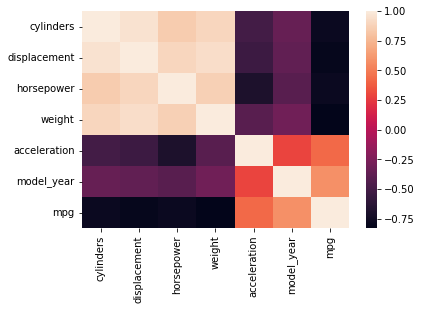

In [222]:
# Heatmap
sns.heatmap(df.corr());

# Use ; or plt.show() to make the "axes subplot" go away.

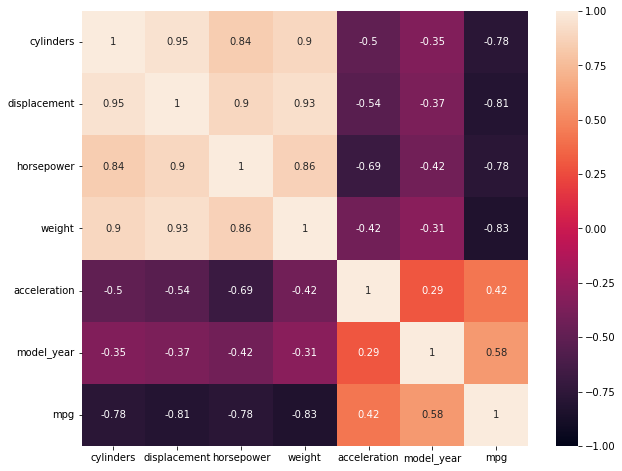

In [255]:
# A bit more beautiful

plt.figure(figsize = (10,8))
sns.heatmap(df.corr(), 
            annot = True, # add numbers
            vmin = -1, # set the scale for the colormap
            vmax = 1);

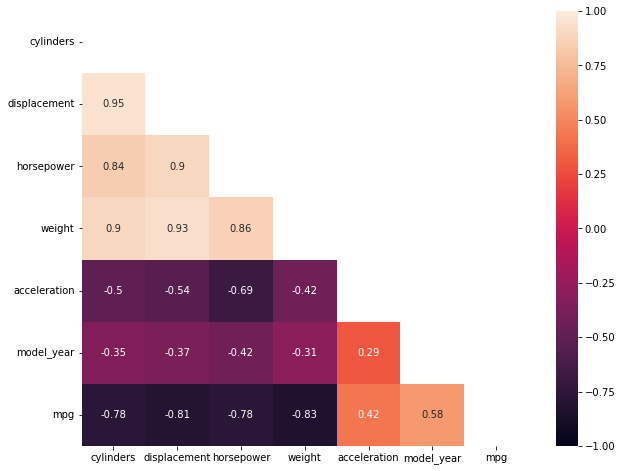

In [224]:
# A bit redundant... let's remove that!

mask = np.zeros_like(df.corr())           # this creates an array that's the same size as the given array
mask[np.triu_indices_from(mask)] = True   # a numpy function, grabs the indices of the upper triangle of the array.

plt.figure(figsize = (10,8))
sns.heatmap(df.corr(), mask = mask, annot = True, vmin = -1, vmax = 1);

In [225]:
# What if we ONLY wanted to look at how the features correlate with `mpg`?

df.corr()[['mpg']] 

# Why two brackets? To make it a dataframe. 
# Shift/tab on heatmap, read about the parameter. It wants 2D data. No series. No tensors

,mpg
cylinders,-0.777618
displacement,-0.805127
horsepower,-0.778427
weight,-0.832244
acceleration,0.423329
model_year,0.580541
mpg,1.000000


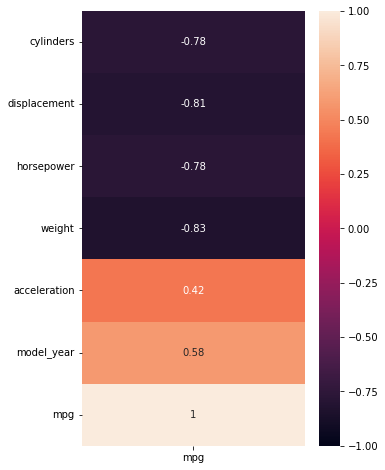

In [226]:
# Can we throw this in a heatmap?

plt.figure(figsize = (5,8))
sns.heatmap(df.corr()[['mpg']], annot = True, vmin = -1, vmax = 1);

#### Take a look at your parameters and play around with them! Ex | vmin, vmax, cmap, etc.



For more Seaborn color palettes, click [here](https://seaborn.pydata.org/tutorial/color_palettes.html).

## Countplots 🔢

**Distribution of Model Year**

''

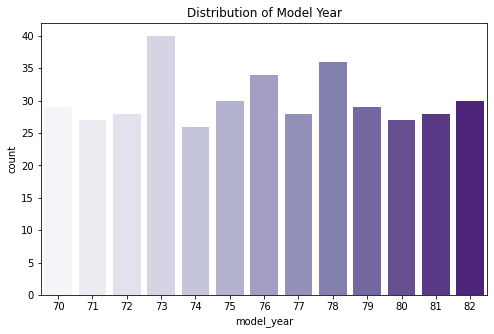

In [253]:
# Using Seaborn

plt.figure(figsize = (8,5))

sns.countplot(data = df, x = 'model_year', palette = 'Purples')
plt.title('Distribution of Model Year', fontsize = 12)
plt.xlabel('Model Year')
plt.ylabel('Count');

*Why can we mix up seaborn and matplotlib like this? Seaborn is using matplotlib under the hood.*

**Distribution of Cylinders**

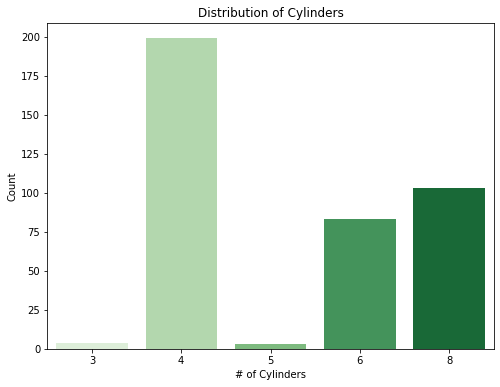

In [235]:
plt.figure(figsize = (8,6))
sns.countplot(data = df, x = 'cylinders', palette = 'Greens')
plt.title('Distribution of Cylinders', fontsize = 12)
plt.xlabel('# of Cylinders')
plt.ylabel('Count');

In [230]:
# How can we get them in order? Use the "order" parameter!

df['cylinders'].value_counts().index

Int64Index([4, 8, 6, 3, 5], dtype='int64')

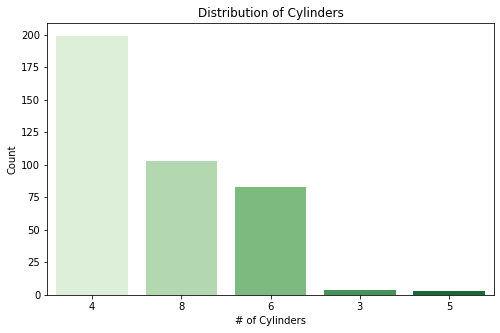

In [234]:
plt.figure(figsize = (8,5))
sns.countplot(data = df,
              x = 'cylinders',
              palette = 'Greens',
              order = df['cylinders'].value_counts().index) 
plt.title('Distribution of Cylinders', fontsize = 12)
plt.xlabel('# of Cylinders')
plt.ylabel('Count');

## Boxplots 📦

**MPG Distribution**

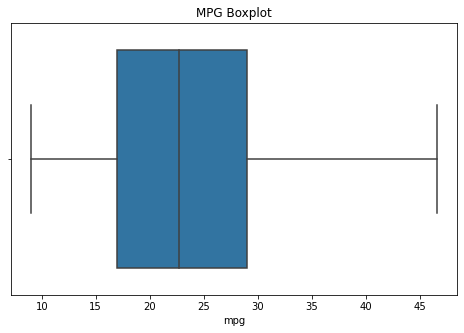

In [238]:
# Seaborn .boxplot()

plt.figure(figsize = (8,5))
sns.boxplot(data = df, x = 'mpg')
plt.title('MPG Boxplot');

In [175]:
# Something looks familiar...
df['mpg'].describe() 

count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

**Weight Distribution**

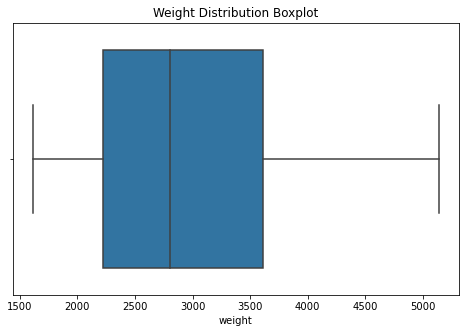

In [239]:
plt.figure(figsize = (8,5))
sns.boxplot(data = df, x = 'weight')
plt.title('Weight Distribution Boxplot');

## Barplots 📊

**Average MPG by Number of Cylinders**

In [176]:
#Let's review... how do we use .groupby()?
df.groupby(by='cylinders').mean()

,displacement,horsepower,weight,acceleration,model_year,mpg
cylinders,,,,,,
3,72.500000,99.250000,2398.500000,13.250000,75.500000,20.550000
4,109.670854,78.281407,2305.110553,16.581910,77.030151,29.283920
5,145.000000,82.333333,3103.333333,18.633333,79.000000,27.366667
6,218.361446,101.506024,3202.120482,16.254217,75.951807,19.973494
8,345.009709,158.300971,4114.718447,12.955340,73.902913,14.963107


In [180]:
# One step further -- we just want the `mpg` column!
df.groupby(by = 'cylinders').mean()[['mpg']]

,mpg
cylinders,
3,20.550000
4,29.283920
5,27.366667
6,19.973494
8,14.963107


<Figure size 576x360 with 0 Axes>

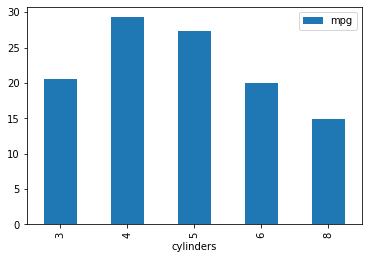

In [242]:
# Quick Plot w/ Pandas
df.groupby(by = 'cylinders').mean()[['mpg']].plot(kind = 'bar');

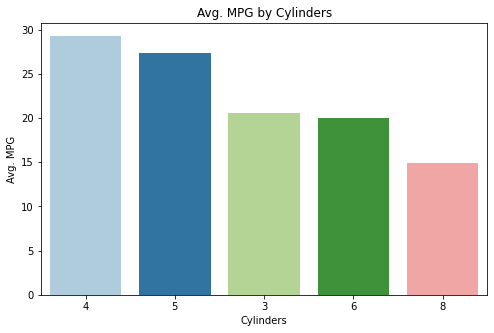

In [241]:
# With Seaborn
plt.figure(figsize = (8,5))
sns.barplot(data=df,
            x = df.groupby(by='cylinders').mean()['mpg'].index,
            y = df.groupby(by='cylinders').mean()['mpg'].values,
            order = df.groupby(by='cylinders').mean()['mpg'].sort_values(ascending=False).index,
            palette = 'Paired'
           )
plt.title('Avg. MPG by Cylinders')
plt.xlabel('Cylinders')
plt.ylabel('Avg. MPG');

## Scatterplots 🐜

**Weight vs. MPG**

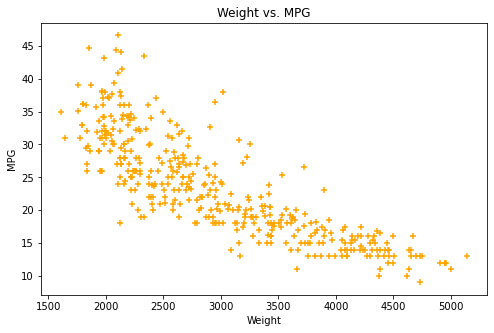

In [243]:
# Matplotlib

plt.figure(figsize = (8,5))
plt.scatter(data = df, x = 'weight', y = 'mpg', marker = '+', color = 'orange')
plt.title('Weight vs. MPG')
plt.xlabel('Weight')
plt.ylabel('MPG');

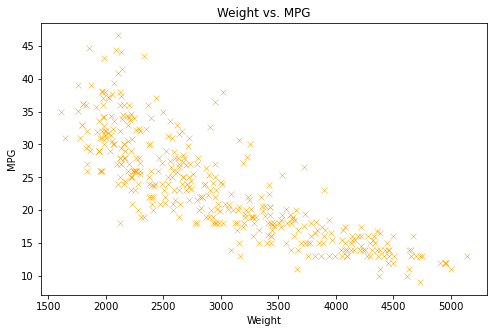

In [244]:
#Seaborn

plt.figure(figsize = (8,5))
sns.scatterplot(data = df, x = 'weight', y = 'mpg', marker='x', color = 'orange')
plt.title('Weight vs. MPG')
plt.xlabel('Weight')
plt.ylabel('MPG');

## Your turn!

In [24]:
# Create more plot(s) of your choosing to help you explore the data

# Upcoming This Week - Machine Learning!

Use Linear Regression to predict `mpg` from the other features<br>